In [1]:
import sys
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib:", matplotlib.__version__)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True,
                     "grid.alpha": 0.2, "figure.dpi": 110})

Python: 3.12.14
NumPy: 2.0.2
pandas: 2.3.3
scikit-learn: 1.6.1
matplotlib: 3.9.4


# Week 2 · Task 1 — Data Preprocessing and Cleaning
**Student surname:** Gumar  
**Seed (last four digits of student ID): 3242**  
MOP 3231 · Machine Learning (Python)

This dataset contains synthetic apartment listings. Its prices are not evidence about the real Almaty market.
The goal is to keep one most recent posting per listing, document the cleaning rules, and prepare features without fitting imputers or scalers on the test set.

## Step 2 — Load and inspect

In [2]:
YOUR_ID = 3242
raw = pd.read_csv("data/almaty_apartments_raw.csv")
ids = raw["listing_id"].drop_duplicates().sample(frac=0.9, random_state=YOUR_ID)
df = raw[raw["listing_id"].isin(ids)].reset_index(drop=True)
print("Raw shape:", raw.shape)
print("Sample shape:", df.shape)
print("Selected unique listings:", len(ids))
print("Types:"); print(df.dtypes)
print("Missing values:"); print(df.isna().sum())
display(df.describe(include="all").T)
for col in ["listed_date", "rooms", "area_m2", "price_kzt"]:
    print(col, "examples:", df[col].sample(10, random_state=YOUR_ID).tolist())
print("Studios:", df.loc[df.rooms.eq("studio"), "rooms"].head().tolist())
print("Areas with units or commas:", df.loc[df.area_m2.str.contains(r"m²|,", regex=True), "area_m2"].head(8).tolist())
print("Prices with formatting:", df.loc[df.price_kzt.str.contains(r"₸|,|\s", regex=True), "price_kzt"].head(8).tolist())
exact_count = int(df.duplicated().sum())
distinct = df.drop_duplicates()
repost_count = int(distinct["listing_id"].duplicated().sum())
print("Exact duplicate rows:", exact_count)
print("Additional nonidentical postings of the same listing:", repost_count)
pair_ids = distinct.loc[distinct["listing_id"].duplicated(keep=False), "listing_id"].drop_duplicates().head(2)
display(distinct[distinct.listing_id.isin(pair_ids)].sort_values(["listing_id", "listed_date"]))
for listing in pair_ids:
    pair = distinct[distinct.listing_id.eq(listing)]
    print(listing, "differing columns:", pair.columns[pair.nunique(dropna=False).gt(1)].tolist())

Raw shape: (1284, 11)
Sample shape: (1154, 11)
Selected unique listings: 1080
Types:
listing_id           object
listed_date          object
district             object
rooms                object
area_m2              object
floor                 int64
total_floors          int64
year_built          float64
building_type        object
ceiling_height_m    float64
price_kzt            object
dtype: object
Missing values:
listing_id            0
listed_date           0
district              0
rooms                 0
area_m2               0
floor                 0
total_floors          0
year_built           52
building_type         0
ceiling_height_m    142
price_kzt             0
dtype: int64
listed_date examples: ['2026-03-25', '2026-07-16', '2026-08-05', '2026-07-05', '2026-08-24', '2026-07-25', '2026-08-16', '2026-08-24', '2026-02-11', '2026-05-01']
rooms examples: ['3', '3', '4', '1', '1', '2', '2', '1', '1', '4']
area_m2 examples: ['75.8', '87.8', '126.6', '40.8', '36.3', '47.7', '5

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
listing_id,1154,1080,ALM-11147,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
listed_date,1154,245,2026-04-18,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
district,1154,47,Medeu,147,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rooms,1154,6,2,431,NaN,NaN,NaN,NaN,NaN,NaN,NaN
area_m2,1154,654,42.0,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
floor,1154.0,NaN,NaN,NaN,5.954939,4.763228,-1.0,2.0,5.0,8.0,30.0
total_floors,1154.0,NaN,NaN,NaN,10.565858,6.083511,3.0,5.0,9.0,12.0,25.0
year_built,1102.0,NaN,NaN,NaN,1950.824864,279.273563,0.0,1973.0,1987.0,2009.75,2024.0
building_type,1154,3,panel,474,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ceiling_height_m,1012.0,NaN,NaN,NaN,2.718379,0.449092,0.0,2.62,2.77,2.91,3.2


,listing_id,listed_date,district,rooms,area_m2,floor,total_floors,year_built,building_type,ceiling_height_m,price_kzt
25,ALM-10643,2026-07-14,Zhetysu,1,42.0,5,5,1980.0,panel,2.67,23250000
255,ALM-10643,2026-08-29,Zhetysu,1,42.0,5,5,1980.0,panel,2.67,21480000
9,ALM-10938,2026-08-10,Medeu,5,133.0,1,9,2013.0,monolith,2.93,177470000
510,ALM-10938,2026-08-21,Medeu,5,133.0,1,9,2013.0,monolith,2.93,167850000


**Types:** `listed_date` is text because `read_csv` does not automatically parse dates. `rooms` includes the word `studio`. `area_m2` includes decimal commas and the unit `m²`. `price_kzt` includes thousands separators, spaces and the tenge symbol. `listing_id`, `district` and `building_type` are correctly stored as text before category cleaning.

**Grain:** one cleaned row represents the most recent dated posting of one unique `listing_id`. The displayed reposts differ in posting date and asking price; file order does not indicate which posting is newer.

### Validation specification
These are checks for this synthetic completed-apartment dataset, not universal property-market limits. Missing predictor values are allowed before imputation; unusually large but possible values must be inspected rather than automatically removed.

| Column | Expected type | Valid values / rule |
|---|---|---|
| listing_id | string | Nonmissing `ALM-` followed by digits; unique after repost resolution |
| listed_date | datetime | Valid date, no later than 2026-09-27 |
| district | category/string | Alatau, Almaly, Auezov, Bostandyk, Medeu, Nauryzbay, Turksib, Zhetysu |
| rooms | integer | 1–20; studio is defined as 1 room |
| area_m2 | float | Positive; review values above 200 m² together with rooms and district price per m² |
| floor | numeric integer or NaN | 1 ≤ floor ≤ total_floors |
| total_floors | integer | 1–100 storeys |
| year_built | numeric integer or NaN | 1800–2026 and no later than the listing year |
| building_type | category/string | panel, brick, monolith |
| ceiling_height_m | float or NaN | 2–6 metres |
| price_kzt | numeric | Positive asking price in KZT |

## Step 3 — Clean and transform

In [3]:
cleaning_log = []
def log(step, operation, before, after, cells=0):
    cleaning_log.append({"Step": step, "Operation": operation,
                         "Rows before": int(before), "Rows after": int(after),
                         "Cells changed": int(cells)})

n = len(df)
df = df.drop_duplicates().copy()
log("3a", "Remove exact duplicate rows", n, len(df))
old = df["listed_date"].copy()
df["listed_date"] = pd.to_datetime(old, errors="coerce")
new_missing = int((old.notna() & df["listed_date"].isna()).sum())
print("New NaNs from date parsing:", new_missing)
assert new_missing == 0
log("3a", "Parse listing dates", len(df), len(df), old.notna().sum())
# The observed data has no ambiguous same-date reposts after exact deduplication.
assert not df.duplicated(["listing_id", "listed_date"]).any()
n = len(df)
df = df.sort_values(["listed_date", "listing_id"]).drop_duplicates("listing_id", keep="last").reset_index(drop=True)
log("3a", "Keep latest dated posting per listing", n, len(df))
print("Reposts resolved:", n-len(df))
print("Remaining duplicate listing IDs:", df.listing_id.duplicated().sum())

New NaNs from date parsing: 0
Reposts resolved: 41
Remaining duplicate listing IDs: 0


Exact copies repeat the same information, so they are removed. For reposts, I keep the posting with the latest parsed date because it gives the most recent asking price. The date check above ensures there is no unresolved same-date conflict.

In [4]:
print("Original district spellings:")
print(df["district"].value_counts().to_string())
canonical = ["Alatau", "Almaly", "Auezov", "Bostandyk", "Medeu", "Nauryzbay", "Turksib", "Zhetysu"]
prefix_map = {
    "alata": "Alatau", "almal": "Almaly", "auezo": "Auezov", "bosta": "Bostandyk",
    "medeu": "Medeu", "naury": "Nauryzbay", "turks": "Turksib", "zhety": "Zhetysu",
    "алата": "Alatau", "алмал": "Almaly", "ауэзо": "Auezov", "боста": "Bostandyk",
    "медеу": "Medeu", "науры": "Nauryzbay", "туркс": "Turksib", "жетыс": "Zhetysu"
}
old = df["district"].copy()
df["district"] = old.str.strip().str.casefold().str[:5].map(prefix_map)
print("Unmapped spellings:", old[df["district"].isna()].unique().tolist())
assert df["district"].isna().sum() == 0
assert set(df["district"].unique()) == set(canonical)
log("3b", "Normalize district spelling/case/whitespace", len(df), len(df), old.ne(df.district).sum())
print("Canonical district count:", df.district.nunique())
print("Missing districts:", df.district.isna().sum())

parsed = {
    "rooms": df["rooms"].str.strip().str.casefold().replace({"studio": "1"}),
    "area_m2": df["area_m2"].str.replace("m²", "", regex=False).str.strip().str.replace(",", ".", regex=False),
    "price_kzt": df["price_kzt"].str.replace(r"[₸,\s]", "", regex=True)
}
for col, values in parsed.items():
    old = df[col].copy()
    df[col] = pd.to_numeric(values, errors="coerce")
    new_missing = int((old.notna() & df[col].isna()).sum())
    print(col, "new NaNs from parsing:", new_missing)
    assert new_missing == 0, f"Unparsed values in {col}"
    log("3c", f"Parse {col} to numeric", len(df), len(df), old.notna().sum())
df["rooms"] = df["rooms"].astype(int)
print(df.dtypes)
display(pd.DataFrame(cleaning_log))

Original district spellings:
district
Medeu            139
Bostandyk        121
Turksib          118
Zhetysu          115
Auezov           113
Almaly           111
Alatau           103
Nauryzbay         94
medeu             10
turksib            9
auezov             8
bostandyk          7
Auezovskiy         7
Наурызбайский      7
 Auezov            7
AUEZOV             7
Alatauskiy         6
Nauryzbayskiy      6
Медеуский          5
 Turksib           5
Bostandykskiy      5
ALMALY             5
nauryzbay          5
Almalinskiy        5
BOSTANDYK          4
TURKSIB            4
 Bostandyk         4
ZHETYSU            4
 Zhetysu           4
MEDEU              4
Zhetysuskiy        3
 Alatau            3
Турксибский        3
 Almaly            3
Бостандыкский      3
almaly             3
ALATAU             3
Ауэзовский         2
Medeuskiy          2
zhetysu            2
 Nauryzbay         2
Turksibskiy        2
NAURYZBAY          2
 Medeu             2
alatau             1
Алатауский       

,Step,Operation,Rows before,Rows after,Cells changed
0,3a,Remove exact duplicate rows,1154,1121,0
1,3a,Parse listing dates,1121,1121,1121
2,3a,Keep latest dated posting per listing,1121,1080,0
3,3b,Normalize district spelling/case/whitespace,1080,1080,166
4,3c,Parse rooms to numeric,1080,1080,1080
5,3c,Parse area_m2 to numeric,1080,1080,1080
6,3c,Parse price_kzt to numeric,1080,1080,1080


I treat a studio as 1 room. A comma in area is a decimal separator, so `65,5` becomes `65.5`; commas in prices are thousands separators and are removed. Unit symbols and price whitespace are removed without deleting decimal points or signs. The parsing checks report unexpected new missing values rather than hiding them.

## Step 4 — Sentinels, impossible values and outliers

In [5]:
display(df.describe().T)
for col in ["floor", "year_built", "ceiling_height_m"]:
    print(col, "smallest values and frequencies:")
    print(df[col].value_counts(dropna=False).sort_index().head(6))
sentinels = {"floor": -1, "year_built": 0, "ceiling_height_m": 0}
for col, sentinel in sentinels.items():
    mask = df[col].eq(sentinel)
    count = int(mask.sum())
    df.loc[mask, col] = np.nan
    log("4", f"Replace {col} sentinel {sentinel} with NaN", len(df), len(df), count)
    print(col, "sentinels replaced:", count)

impossible_floor = df["floor"] > df["total_floors"]
print("Impossible floor > total_floors:", impossible_floor.sum())
display(df.loc[impossible_floor, ["listing_id", "floor", "total_floors"]])
count_impossible = int(impossible_floor.sum())
df.loc[impossible_floor, "floor"] = np.nan
log("4", "Set contradictory floor to NaN", len(df), len(df), count_impossible)

checks = {
    "bad listing_id": ~df.listing_id.str.fullmatch(r"ALM-\d+", na=False),
    "duplicate listing_id": df.listing_id.duplicated(),
    "bad listed_date": df.listed_date.isna() | df.listed_date.gt(pd.Timestamp("2026-09-27")),
    "bad district": ~df.district.isin(canonical),
    "bad rooms": ~df.rooms.between(1, 20) | df.rooms.mod(1).ne(0),
    "bad area": df.area_m2.isna() | df.area_m2.le(0),
    "bad floor": df.floor.notna() & (~df.floor.ge(1) | df.floor.gt(df.total_floors) | df.floor.mod(1).ne(0)),
    "bad total_floors": ~df.total_floors.between(1, 100) | df.total_floors.mod(1).ne(0),
    "bad year_built": df.year_built.notna() & (~df.year_built.between(1800, 2026) | df.year_built.gt(df.listed_date.dt.year) | df.year_built.mod(1).ne(0)),
    "bad building_type": ~df.building_type.isin(["panel", "brick", "monolith"]),
    "bad ceiling": df.ceiling_height_m.notna() & ~df.ceiling_height_m.between(2, 6),
    "bad price": df.price_kzt.isna() | df.price_kzt.le(0)
}
print("Remaining validation violations:")
print(pd.Series({name: int(mask.sum()) for name, mask in checks.items()}))
assert not any(mask.any() for mask in checks.values())

floor smallest values and frequencies:
floor
-1     10
 1    138
 2    126
 3    149
 4    104
 5    107
Name: count, dtype: int64
year_built smallest values and frequencies:
year_built
0.0       21
1950.0     3
1951.0     2
1952.0     5
1953.0     5
1954.0     3
Name: count, dtype: int64
ceiling_height_m smallest values and frequencies:
ceiling_height_m
0.00    22
2.50     6
2.51    21
2.52    19
2.53    27
2.54    10
Name: count, dtype: int64
floor sentinels replaced: 10
year_built sentinels replaced: 21
ceiling_height_m sentinels replaced: 22
Impossible floor > total_floors: 10
Remaining validation violations:
bad listing_id          0
duplicate listing_id    0
bad listed_date         0
bad district            0
bad rooms               0
bad area                0
bad floor               0
bad total_floors        0
bad year_built          0
bad building_type       0
bad ceiling             0
bad price               0
dtype: int64


,count,mean,min,25%,50%,75%,max,std
listed_date,1080,2026-05-01 01:48:00,2026-01-01 00:00:00,2026-03-05 00:00:00,2026-04-29 00:00:00,2026-06-29 00:00:00,2026-08-31 00:00:00,NaN
rooms,1080.0,2.265741,1.0,2.0,2.0,3.0,5.0,1.008184
area_m2,1080.0,69.1825,25.3,45.275,58.6,79.425,879.0,60.325603
floor,1080.0,5.942593,-1.0,2.0,5.0,8.0,30.0,4.780292
total_floors,1080.0,10.57037,3.0,5.0,9.0,12.0,25.0,6.131449
year_built,1031.0,1949.838021,0.0,1973.0,1987.0,2009.0,2024.0,282.001026
ceiling_height_m,948.0,2.718059,0.0,2.62,2.77,2.91,3.2,0.453446
price_kzt,1080.0,46603138.888889,11440000.0,28402500.0,40275000.0,57682500.0,193000000.0,25285513.020889


,listing_id,floor,total_floors
8,ALM-10729,15.0,12
115,ALM-10851,13.0,12
140,ALM-10944,4.0,3
307,ALM-10044,30.0,25
574,ALM-10420,11.0,9
620,ALM-10636,6.0,5
699,ALM-10628,6.0,5
757,ALM-10321,10.0,5
834,ALM-10266,13.0,12
1008,ALM-10695,14.0,12


The sentinel values are placeholders, not real measurements. For a floor above the number of storeys, either field could be wrong. I set the apartment floor to missing and retain the otherwise valid row and building height; this is an explicit working assumption, not a claim that the true floor is known.

Global fences: -85,460 to 1,527,464 KZT/m²
Globally flagged rows: 0
District-level flagged rows: 12


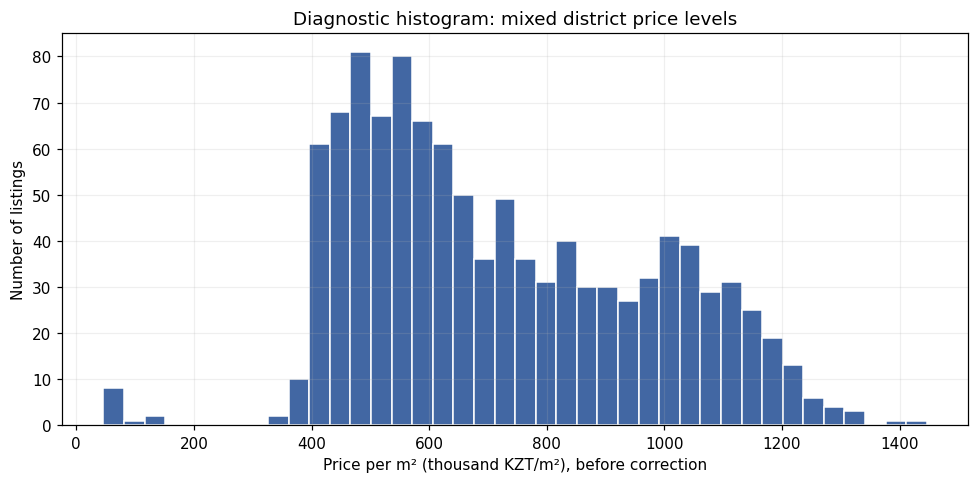

,listing_id,district,rooms,area_m2,price_kzt,price_per_m2
1047,ALM-10659,Turksib,2,544.0,25030000,46011.029412
167,ALM-10405,Turksib,1,356.0,18830000,52893.258427
950,ALM-10440,Auezov,3,879.0,48370000,55028.441411
150,ALM-10276,Turksib,2,604.0,33630000,55678.807947
770,ALM-10909,Alatau,2,565.0,32610000,57716.814159
514,ALM-10921,Zhetysu,3,668.0,38560000,57724.550898
207,ALM-11122,Zhetysu,2,647.0,40670000,62859.350850
3,ALM-10910,Zhetysu,3,736.0,54050000,73437.500000
655,ALM-10264,Bostandyk,1,495.0,42680000,86222.222222
315,ALM-10058,Bostandyk,2,555.0,66270000,119405.405405


In [6]:
df["price_per_m2"] = df["price_kzt"] / df["area_m2"]
df["area_before_fix"] = df["area_m2"]
def fences(values, groups=None):
    grouped = values if groups is None else values.groupby(groups)
    q1, q3 = grouped.quantile(0.25), grouped.quantile(0.75)
    if groups is not None:
        q1, q3 = groups.map(q1), groups.map(q3)
    iqr = q3-q1
    return q1-1.5*iqr, q3+1.5*iqr

global_low, global_high = fences(df["price_per_m2"])
global_flag = (df.price_per_m2 < global_low) | (df.price_per_m2 > global_high)
low, high = fences(df["price_per_m2"], df["district"])
group_flag = (df.price_per_m2 < low) | (df.price_per_m2 > high)
print(f"Global fences: {global_low:,.0f} to {global_high:,.0f} KZT/m²")
print("Globally flagged rows:", int(global_flag.sum()))
print("District-level flagged rows:", int(group_flag.sum()))
plt.hist(df.price_per_m2 / 1000, bins=40, color="#4267a3", edgecolor="white")
plt.xlabel("Price per m² (thousand KZT/m²), before correction")
plt.ylabel("Number of listings")
plt.title("Diagnostic histogram: mixed district price levels")
plt.tight_layout(); plt.show()
display(df.loc[group_flag, ["listing_id", "district", "rooms", "area_m2", "price_kzt", "price_per_m2"]].sort_values("price_per_m2"))

Global IQR fences combine districts with different price levels, making the interval too wide to detect some locally abnormal prices per m². District-level fences compare more similar listings. I use them as inspection flags; they do not automatically justify deleting a row.

In [7]:
# A proposed factor-of-ten area correction must pass three independent plausibility checks.
candidate_area = df["area_m2"] / 10
candidate_ppm = df["price_kzt"] / candidate_area
fix_area = (group_flag & df.price_per_m2.lt(low)
            & df.area_m2.gt(200) & (df.area_m2 / df.rooms).gt(100)
            & (candidate_area / df.rooms).between(10, 60)
            & candidate_ppm.ge(low) & candidate_ppm.le(high))
audit = df.loc[fix_area, ["listing_id", "district", "rooms", "area_m2", "price_per_m2"]].copy()
audit["area_after_m2"] = candidate_area[fix_area]
audit["price_per_m2_after"] = candidate_ppm[fix_area]
audit["district_low"] = low[fix_area]
audit["district_high"] = high[fix_area]
print("Area corrections:", int(fix_area.sum()))
display(audit)
assert audit.price_per_m2_after.between(audit.district_low, audit.district_high).all()
kept_flagged = df.loc[group_flag & ~fix_area, ["listing_id", "district", "rooms", "area_m2", "price_kzt", "price_per_m2"]].copy()
print("Flagged rows retained without correction:", len(kept_flagged))
display(kept_flagged)
df.loc[fix_area, "area_m2"] = candidate_area[fix_area]
log("4", "Correct supported factor-of-ten area errors", len(df), len(df), fix_area.sum())
old_ppm = df["price_per_m2"].copy()
df["price_per_m2"] = df["price_kzt"] / df["area_m2"]
log("4", "Recompute price_per_m2 after area corrections", len(df), len(df), old_ppm.ne(df.price_per_m2).sum())
log("4", "Keep plausible statistical outliers; drop none", len(df), len(df), 0)
df.to_csv("data/almaty_apartments_clean.csv", index=False)
print("Saved clean data before imputation:", df.shape)
print("Remaining missing values:"); print(df.isna().sum())

Area corrections: 11
Flagged rows retained without correction: 1
Saved clean data before imputation: (1080, 13)
Remaining missing values:
listing_id            0
listed_date           0
district              0
rooms                 0
area_m2               0
floor                20
total_floors          0
year_built           70
building_type         0
ceiling_height_m    154
price_kzt             0
price_per_m2          0
area_before_fix       0
dtype: int64


,listing_id,district,rooms,area_m2,price_per_m2,area_after_m2,price_per_m2_after,district_low,district_high
3,ALM-10910,Zhetysu,3,736.0,73437.500000,73.6,7.343750e+05,373001.965835,8.753655e+05
150,ALM-10276,Turksib,2,604.0,55678.807947,60.4,5.567881e+05,288086.303940,7.666354e+05
167,ALM-10405,Turksib,1,356.0,52893.258427,35.6,5.289326e+05,288086.303940,7.666354e+05
207,ALM-11122,Zhetysu,2,647.0,62859.350850,64.7,6.285935e+05,373001.965835,8.753655e+05
245,ALM-10072,Medeu,2,530.0,121264.150943,53.0,1.212642e+06,640626.723921,1.470480e+06
315,ALM-10058,Bostandyk,2,555.0,119405.405405,55.5,1.194054e+06,541630.860252,1.372954e+06
514,ALM-10921,Zhetysu,3,668.0,57724.550898,66.8,5.772455e+05,373001.965835,8.753655e+05
655,ALM-10264,Bostandyk,1,495.0,86222.222222,49.5,8.622222e+05,541630.860252,1.372954e+06
770,ALM-10909,Alatau,2,565.0,57716.814159,56.5,5.771681e+05,292875.689310,6.630688e+05
950,ALM-10440,Auezov,3,879.0,55028.441411,87.9,5.502844e+05,423597.982678,8.964121e+05


,listing_id,district,rooms,area_m2,price_kzt,price_per_m2
842,ALM-10605,Nauryzbay,2,54.3,36960000,680662.983425


**Correct:** the displayed huge areas occur in small room-count apartments and produce district prices per m² about one order of magnitude too low. Dividing area by 10 gives reasonable area per room and puts every corrected price per m² inside its original district fences, as the audit table checks. This supports a decimal-place error; it is an inference from the data, not externally confirmed ground truth.

**Keep:** the remaining flagged rows have plausible areas, room counts and positive prices. A locally unusual price alone is not sufficient evidence of an error, so I keep them unchanged. **Drop:** no row is dropped merely because it is an outlier.

`area_before_fix` is retained only for the requested scaler demonstration. `price_per_m2` uses the target and is never a model feature. The CSV above contains missing values and is saved before any imputation. The full-sample outlier audit follows Step 4 of the assignment; because it uses prices and sample-derived fences, the later R² is a lab sanity check rather than a completely untouched production holdout estimate.

## Step 5 — Missing data: split, diagnose, compare and fill

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

NUMERIC = ["rooms", "area_m2", "floor", "total_floors", "year_built", "ceiling_height_m"]
train, test = train_test_split(df, test_size=0.2, random_state=YOUR_ID)
train, test = train.copy(), test.copy()
assert set(train.listing_id).isdisjoint(set(test.listing_id))
print("Train/test rows:", len(train), len(test))
display(pd.DataFrame({"train_missing": train[NUMERIC].isna().sum(),
                      "test_missing": test[NUMERIC].isna().sum()}))
top_missing = train[NUMERIC].isna().sum().sort_values(ascending=False).head(2).index
for col in top_missing:
    rates = train.assign(missing=train[col].isna()).groupby("building_type")["missing"].agg(["mean", "sum", "count"])
    print("Missingness:", col)
    display(rates.rename(columns={"mean": "missing_rate", "sum": "missing_count", "count": "group_rows"}))
    spread = rates["mean"].max()-rates["mean"].min()
    verdict = "MAR-like: rates depend strongly on observed building type" if spread > 0.10 else "MCAR-like across building types: rates are relatively similar"
    print(f"{col}: {verdict}; rate range {rates['mean'].min():.1%}–{rates['mean'].max():.1%}.")
print("Training rows removed by dropna():", len(train)-len(train.dropna()))
print("Training rows removed by dropping missing numeric predictors:", train[NUMERIC].isna().any(axis=1).sum())

Train/test rows: 864 216
Missingness: ceiling_height_m
ceiling_height_m: MAR-like: rates depend strongly on observed building type; rate range 4.1%–23.1%.
Missingness: year_built
year_built: MCAR-like across building types: rates are relatively similar; rate range 5.8%–7.2%.
Training rows removed by dropna(): 189
Training rows removed by dropping missing numeric predictors: 189


,train_missing,test_missing
rooms,0,0
area_m2,0,0
floor,16,4
total_floors,0,0
year_built,55,15
ceiling_height_m,128,26


,missing_rate,missing_count,group_rows
building_type,,,
brick,0.156951,35,223
monolith,0.041237,12,291
panel,0.231429,81,350


,missing_rate,missing_count,group_rows
building_type,,,
brick,0.071749,16,223
monolith,0.058419,17,291
panel,0.062857,22,350


The missing-rate comparisons describe evidence consistent with MCAR or MAR, not a proof of the mechanism. Similar rates across building types cannot rule out dependence on other variables or on the missing value itself (MNAR). Dropping all incomplete rows would lose usable information and could distort the building-type mix.

In [9]:
known = train[train["ceiling_height_m"].notna()]
hidden = known.sample(frac=0.15, random_state=YOUR_ID).index
rest = train.drop(index=hidden)
answers = train.loc[hidden, "ceiling_height_m"]
global_median = rest["ceiling_height_m"].median()
group_medians = rest.groupby("building_type")["ceiling_height_m"].median()
pred_global = pd.Series(global_median, index=hidden)
pred_group = train.loc[hidden, "building_type"].map(group_medians).fillna(global_median)
mae_global = mean_absolute_error(answers, pred_global)
mae_group = mean_absolute_error(answers, pred_group)
print("Values hidden:", len(hidden))
print(f"Global median MAE: {mae_global:.5f} m")
print(f"Building-type median MAE: {mae_group:.5f} m")
ceiling_strategy = "group" if mae_group < mae_global else "global"
print("Winning ceiling strategy:", ceiling_strategy)

Values hidden: 110
Global median MAE: 0.14627 m
Building-type median MAE: 0.06923 m
Winning ceiling strategy: group


For ceiling height, I use the strategy with lower MAE in the training-only masking experiment. For year built, I use building-type medians because construction periods differ between panel, brick and monolith buildings; a global median is the fallback. For floor, I use the training median floor and cap the filled value at the building height so imputation cannot create a new impossible floor.

In [10]:
# Learn all fill values once, from the unfilled training set only.
train_unfilled = train.copy()
global_fills = train_unfilled[NUMERIC].median()
year_by_type = train_unfilled.groupby("building_type")["year_built"].median().round()
ceiling_by_type = train_unfilled.groupby("building_type")["ceiling_height_m"].median()
floor_fill = int(round(global_fills["floor"]))
print("Training global medians:"); print(global_fills)
print("Training year medians by building type:"); print(year_by_type)
print("Training ceiling medians by building type:"); print(ceiling_by_type)

for name, frame in [("train", train), ("test", test)]:
    for col in ["ceiling_height_m", "year_built", "floor"]:
        missing = frame[col].isna()
        count = int(missing.sum())
        if col == "ceiling_height_m":
            values = frame.building_type.map(ceiling_by_type) if ceiling_strategy == "group" else pd.Series(global_fills[col], index=frame.index)
            frame[col] = frame[col].fillna(values).fillna(global_fills[col])
        elif col == "year_built":
            frame[col] = frame[col].fillna(frame.building_type.map(year_by_type)).fillna(round(global_fills[col]))
        else:
            frame.loc[missing, col] = np.minimum(floor_fill, frame.loc[missing, "total_floors"])
        log("5d", f"{name}: impute {col} using training statistics", len(frame), len(frame), count)
    assert frame[NUMERIC].isna().sum().sum() == 0
    assert frame.floor.between(1, frame.total_floors).all()
    print(name, "remaining numeric NaNs:", frame[NUMERIC].isna().sum().sum())

Training global medians:
rooms                  2.000
area_m2               58.250
floor                  4.500
total_floors           9.000
year_built          1988.000
ceiling_height_m       2.785
dtype: float64
Training year medians by building type:
building_type
brick       1980.0
monolith    2014.0
panel       1977.0
Name: year_built, dtype: float64
Training ceiling medians by building type:
building_type
brick       2.93
monolith    2.86
panel       2.60
Name: ceiling_height_m, dtype: float64
train remaining numeric NaNs: 0
test remaining numeric NaNs: 0


## Step 6 — Scaling, encoding and model sanity check

In [11]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression

scaler_results = []
for scaler in (StandardScaler(), MinMaxScaler(), RobustScaler()):
    scaled = scaler.fit_transform(train[["area_before_fix"]]).ravel()
    q1, q3 = np.percentile(scaled, [25, 75])
    scaler_results.append({"scaler": type(scaler).__name__, "IQR": q3-q1,
                           "minimum": scaled.min(), "maximum": scaled.max()})
display(pd.DataFrame(scaler_results).round(4))

,scaler,IQR,minimum,maximum
0,StandardScaler,0.5391,-0.7057,12.8303
1,MinMaxScaler,0.0398,0.0000,1.0000
2,RobustScaler,1.0000,-0.9779,24.1309


StandardScaler uses a mean and standard deviation inflated by the bad areas, so the central observations occupy a smaller spread. MinMaxScaler lets the largest bad area define 1 and compresses most normal apartments toward 0. RobustScaler uses the median and IQR, leaving the central IQR equal to 1; I would prefer it if these outliers could not be corrected, although scaling alone does not repair erroneous measurements.

In [12]:
correct_scaler = StandardScaler().fit(train[["area_m2"]])
leaky_scaler = StandardScaler().fit(pd.concat([train, test])[["area_m2"]])
correct_mean = correct_scaler.transform(test[["area_m2"]]).mean()
leaky_mean = leaky_scaler.transform(test[["area_m2"]]).mean()
print(f"Scaled test mean, train-only fit: {correct_mean:.6f}")
print(f"Scaled test mean, combined fit:   {leaky_mean:.6f}")

Scaled test mean, train-only fit: 0.010554
Scaled test mean, combined fit:   0.008459


The combined fit leaks the test distribution into preprocessing, even if the difference between the two displayed means is small. It is shown only as a demonstration and is not used below.

In [13]:
CATEGORICAL = ["district", "building_type"]
pre = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL)
])
X_train = pre.fit_transform(train[NUMERIC + CATEGORICAL])
X_test = pre.transform(test[NUMERIC + CATEGORICAL])
model = LinearRegression().fit(X_train, train["price_kzt"])
score = model.score(X_test, test["price_kzt"])
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("NaN counts:", np.isnan(X_train).sum(), np.isnan(X_test).sum())
print(f"Test R²: {score:.6f}")
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
residuals = test[["listing_id", "district", "rooms", "area_m2", "price_kzt"]].copy()
residuals["predicted_price_kzt"] = model.predict(X_test)
residuals["absolute_residual_kzt"] = abs(residuals.price_kzt-residuals.predicted_price_kzt)
print("Largest absolute test residuals (diagnostic only):")
display(residuals.nlargest(5, "absolute_residual_kzt"))
print("This is a preprocessing sanity check, not a tuned model. No changes are selected using these residuals.")

X_train shape: (864, 17)
X_test shape: (216, 17)
NaN counts: 0 0
Test R²: 0.910490
Largest absolute test residuals (diagnostic only):
This is a preprocessing sanity check, not a tuned model. No changes are selected using these residuals.


,listing_id,district,rooms,area_m2,price_kzt,predicted_price_kzt,absolute_residual_kzt
163,ALM-10534,Medeu,5,136.1,159220000,1.194964e+08,3.972365e+07
267,ALM-11081,Medeu,5,115.3,141880000,1.131326e+08,2.874743e+07
975,ALM-11102,Nauryzbay,4,126.6,49960000,7.427843e+07,2.431843e+07
211,ALM-11128,Almaly,4,145.9,148590000,1.279778e+08,2.061223e+07
593,ALM-10955,Medeu,4,92.8,105250000,8.564274e+07,1.960726e+07


## Step 7 — EDA on cleaned, unfilled data

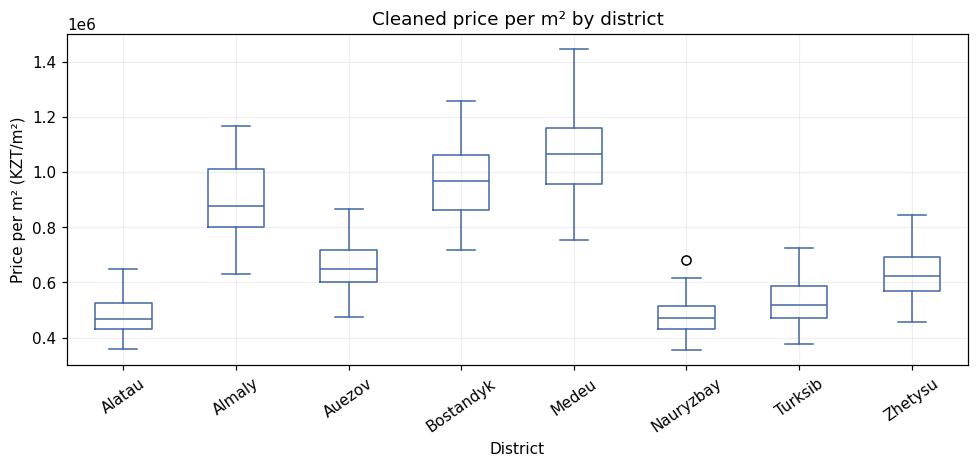

Observation: Medeu has the highest district median (1,064,354 KZT/m²), while Alatau has the lowest (467,442 KZT/m²).


In [14]:
df.boxplot(column="price_per_m2", by="district", rot=35, color="#4267a3")
plt.xlabel("District")
plt.ylabel("Price per m² (KZT/m²)")
plt.title("Cleaned price per m² by district")
plt.suptitle("")
plt.tight_layout(); plt.show()
medians = df.groupby("district")["price_per_m2"].median()
print(f"Observation: {medians.idxmax()} has the highest district median ({medians.max():,.0f} KZT/m²), while {medians.idxmin()} has the lowest ({medians.min():,.0f} KZT/m²).")

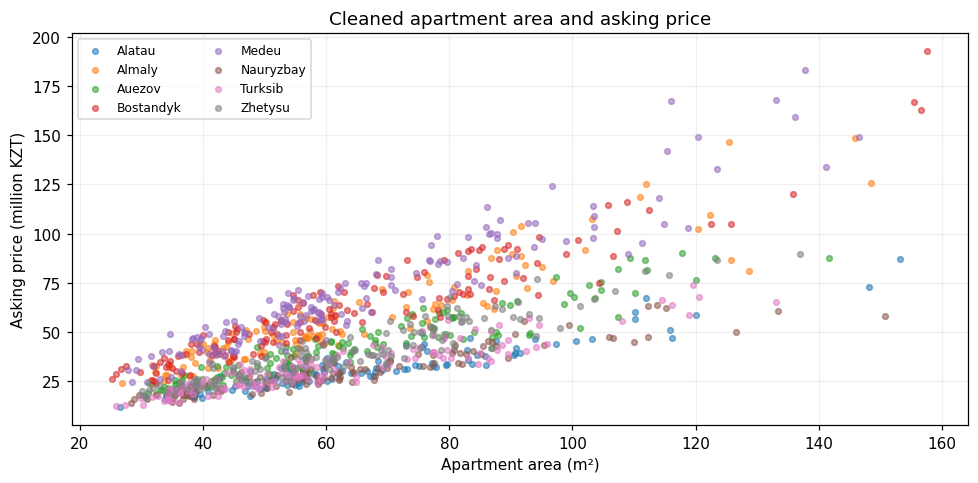

Observation: area and asking price have a positive Pearson correlation of 0.749 across 1,080 cleaned listings.


In [15]:
fig, ax = plt.subplots()
for district, group in df.groupby("district"):
    ax.scatter(group.area_m2, group.price_kzt/1e6, s=14, alpha=0.55, label=district)
ax.set_xlabel("Apartment area (m²)")
ax.set_ylabel("Asking price (million KZT)")
ax.set_title("Cleaned apartment area and asking price")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout(); plt.show()
print(f"Observation: area and asking price have a positive Pearson correlation of {df.area_m2.corr(df.price_kzt):.3f} across {len(df):,} cleaned listings.")

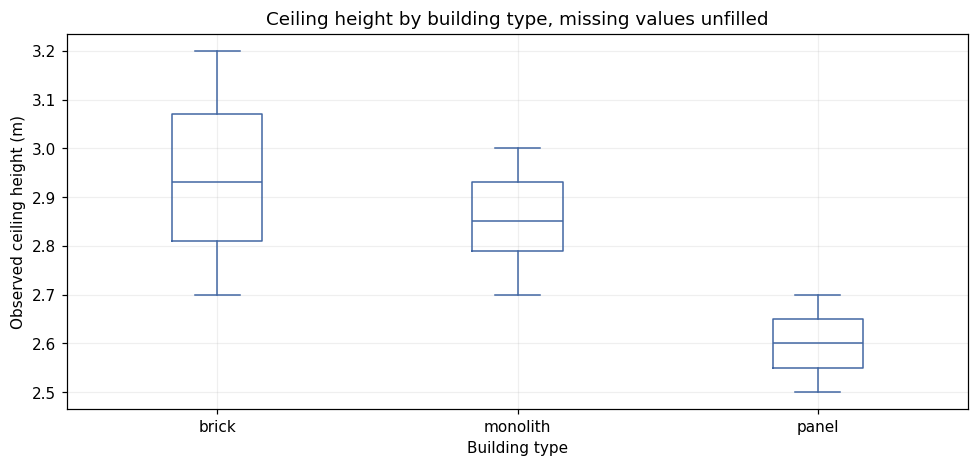

Observation: median observed ceiling height is 2.60 m in panel, 2.93 m in brick, and 2.85 m in monolith buildings.


In [16]:
df.boxplot(column="ceiling_height_m", by="building_type", color="#4267a3")
plt.xlabel("Building type")
plt.ylabel("Observed ceiling height (m)")
plt.title("Ceiling height by building type, missing values unfilled")
plt.suptitle("")
plt.tight_layout(); plt.show()
heights = df.groupby("building_type")["ceiling_height_m"].median()
print(f"Observation: median observed ceiling height is {heights['panel']:.2f} m in panel, {heights['brick']:.2f} m in brick, and {heights['monolith']:.2f} m in monolith buildings.")

### Complete cleaning log
For row deletions, `Cells changed` is 0: the row-count change records the removal. Parsing counts nonmissing cells converted to a new type. Step 5 entries describe separate train/test copies and do not change the saved pre-imputation CSV.

In [17]:
display(pd.DataFrame(cleaning_log))
clean_path = Path("data/almaty_apartments_clean.csv")
assert clean_path.exists()
saved = pd.read_csv(clean_path)
assert len(saved) == len(df)
assert saved.listing_id.is_unique
assert saved[NUMERIC].isna().sum().equals(df[NUMERIC].isna().sum())
print("Clean CSV saved:", clean_path)
print("Rows:", len(saved), "| columns:", saved.shape[1])
print("Missing numeric cells in saved pre-imputation CSV:", saved[NUMERIC].isna().sum().sum())
print("Missing numeric cells in model inputs:", np.isnan(X_train).sum()+np.isnan(X_test).sum())

Clean CSV saved: data/almaty_apartments_clean.csv
Rows: 1080 | columns: 13
Missing numeric cells in saved pre-imputation CSV: 244
Missing numeric cells in model inputs: 0


,Step,Operation,Rows before,Rows after,Cells changed
0,3a,Remove exact duplicate rows,1154,1121,0
1,3a,Parse listing dates,1121,1121,1121
2,3a,Keep latest dated posting per listing,1121,1080,0
3,3b,Normalize district spelling/case/whitespace,1080,1080,166
4,3c,Parse rooms to numeric,1080,1080,1080
5,3c,Parse area_m2 to numeric,1080,1080,1080
6,3c,Parse price_kzt to numeric,1080,1080,1080
7,4,Replace floor sentinel -1 with NaN,1080,1080,10
8,4,Replace year_built sentinel 0 with NaN,1080,1080,21
9,4,Replace ceiling_height_m sentinel 0 with NaN,1080,1080,22


### Git history
The final cell prints the real local project history. After committing the executed notebook, push the repository and submit the URL of the final commit.

In [18]:
!git log --oneline

4b7bc7c (HEAD -> main) Add train-only imputation, scaling and EDA workflow
e037969 Add inspection, validation and documented cleaning rules
3313424 Initialize project and pinned data dependencies
